Connected to fvc_structure (Python 3.10.18)

In [ ]:
##test 2 ----> L2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates, gaussian_filter
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
# GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
GEFOLKI_PYTHON_PATH = '/home/nvidia/projects/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)
    
# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = -1

# --- KEY PARAMETER: Control smoothing of the flow field ---
# This is the most important parameter for fixing holes.
# Start with a value like 2.0.
# Increase it (e.g., 3.0, 4.0) if holes persist.
# Decrease it (e.g., 1.0) if the correction seems "blurry" or "damped".
GAUSSIAN_SIGMA = 3.0  #2.0 (resonable) #1.0 (less smoothing, more detail but risk holes)

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
#L2
# LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c.las")
LAS_INPUT_PATH = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/cloud2d765c57b8471e2c.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
# L2
# REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")
REFERENCE_GRID_PATH = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")


# The displacement fields calculated by gefolki
# L1
# FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
# FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

#L2
FLOW_U_PATH = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/flow_u_03_l2.npy")
FLOW_V_PATH = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/flow_v_03_l2.npy")


# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                #    We clip to W-1 and H-1 because interpolation needs valid neighbors.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                #
                #    --- IMPROVEMENT ---
                #    Using order=3 (bicubic) gives a much smoother interpolation
                #    than order=1 (bilinear) or order=2 (quadratic),
                #    which further helps prevent artifacts.
                # du_pix = map_coordinates(flow_u, coords, order=3, mode="reflect")
                # dv_pix = map_coordinates(flow_v, coords, order=3, mode="reflect")
                du_pix = map_coordinates(flow_u, coords, order=2, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=2, mode="nearest")
                # du_pix = map_coordinates(flow_u, coords, order=3, mode="nearest")
                # dv_pix = map_coordinates(flow_v, coords, order=3, mode="nearest")


                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u_raw = np.load(FLOW_U_PATH)
    v_raw = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- NEW: Smooth the flow fields ---
    # This is the key step to prevent holes.
    # Noisy, pixel-to-pixel variations in the flow field can "rip"
    # the dense point cloud apart, creating gaps. Smoothing
    # ensures the displacement is locally consistent.
    print(f"Smoothing flow fields with Gaussian filter (sigma={GAUSSIAN_SIGMA})...")
    u_smooth = gaussian_filter(u_raw, sigma=GAUSSIAN_SIGMA)
    v_smooth = gaussian_filter(v_raw, sigma=GAUSSIAN_SIGMA)
    print("Smoothing complete.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u_smooth,  # Pass the SMOOTHED u-flow
        flow_v=v_smooth,  # Pass the SMOOTHED v-flow
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
Smoothing flow fields with Gaussian filter (sigma=3.0)...
Smoothing complete.
--- Applying Full Non-Linear Correction (Direction: -1) ---


Applying Full Flow: 100%|██████████| 181506517/181506517 [16:06<00:00, 187774.51pts/s]


✅ Full coregistration complete in 966.66 seconds.
   Saved final point cloud to: /data/calperumResearch/site1_1_DD0001/lidar_l2/cloud2d765c57b8471e2c_coreg.las


In [ ]:
##test 2 ----> L2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates, gaussian_filter
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
# GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
GEFOLKI_PYTHON_PATH = '/home/nvidia/projects/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)
    
# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = -1

# --- KEY PARAMETER: Control smoothing of the flow field ---
# This is the most important parameter for fixing holes.
# Start with a value like 2.0.
# Increase it (e.g., 3.0, 4.0) if holes persist.
# Decrease it (e.g., 1.0) if the correction seems "blurry" or "damped".
GAUSSIAN_SIGMA = 3.0  #2.0 (resonable) #1.0 (less smoothing, more detail but risk holes)

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
#L2 + site 1
# LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c.las")
# LAS_INPUT_PATH = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/cloud2d765c57b8471e2c.las")

#L2 + site 11
LAS_INPUT_PATH = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
# L2 + site 1
# REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")
# REFERENCE_GRID_PATH = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")

# L2 + site 11
REFERENCE_GRID_PATH = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/crop_to_rgb/SASMDD0011_l2_dsm_03_coreg.tif")


# The displacement fields calculated by gefolki
#L2 + site 1
# FLOW_U_PATH = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/flow_u_03_l2.npy")
# FLOW_V_PATH = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/flow_v_03_l2.npy")

#L2 + site 11
FLOW_U_PATH = Path("/data/calperumResearch/site2_1_DD0011/imagery/dsm/flow_u_03_l2.npy")
FLOW_V_PATH = Path("/data/calperumResearch/site2_1_DD0011/imagery/dsm/flow_v_03_l2.npy")


# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                #    We clip to W-1 and H-1 because interpolation needs valid neighbors.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                #
                #    --- IMPROVEMENT ---
                #    Using order=3 (bicubic) gives a much smoother interpolation
                #    than order=1 (bilinear) or order=2 (quadratic),
                #    which further helps prevent artifacts.
                # du_pix = map_coordinates(flow_u, coords, order=3, mode="reflect")
                # dv_pix = map_coordinates(flow_v, coords, order=3, mode="reflect")
                du_pix = map_coordinates(flow_u, coords, order=2, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=2, mode="nearest")
                # du_pix = map_coordinates(flow_u, coords, order=3, mode="nearest")
                # dv_pix = map_coordinates(flow_v, coords, order=3, mode="nearest")


                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u_raw = np.load(FLOW_U_PATH)
    v_raw = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- NEW: Smooth the flow fields ---
    # This is the key step to prevent holes.
    # Noisy, pixel-to-pixel variations in the flow field can "rip"
    # the dense point cloud apart, creating gaps. Smoothing
    # ensures the displacement is locally consistent.
    print(f"Smoothing flow fields with Gaussian filter (sigma={GAUSSIAN_SIGMA})...")
    u_smooth = gaussian_filter(u_raw, sigma=GAUSSIAN_SIGMA)
    v_smooth = gaussian_filter(v_raw, sigma=GAUSSIAN_SIGMA)
    print("Smoothing complete.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u_smooth,  # Pass the SMOOTHED u-flow
        flow_v=v_smooth,  # Pass the SMOOTHED v-flow
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
Smoothing flow fields with Gaussian filter (sigma=3.0)...
Smoothing complete.
--- Applying Full Non-Linear Correction (Direction: -1) ---


Applying Full Flow: 100%|██████████| 69596825/69596825 [02:34<00:00, 450976.52pts/s]


✅ Full coregistration complete in 154.37 seconds.
   Saved final point cloud to: /data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868_coreg.las


## Before/After Coregistration Comparison

In [6]:
import laspy
import numpy as np
from pathlib import Path

print("=" * 80)
print("LAS COREGISTRATION COMPARISON")
print("=" * 80)

# File paths
#site1
las_original = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/cloud2d765c57b8471e2c.las")
las_coregistered = "/data/calperumResearch/site1_1_DD0001/lidar_l2/cloud2d765c57b8471e2c_coreg.las"

#site11
# las_original = "/data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868.las"
# las_coregistered = "/data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868_coreg.las"

print("\n📊 ORIGINAL LAS FILE:")
with laspy.open(las_original) as las:
    header = las.header
    print(f"   Point count:   {header.point_count:,}")
    print(f"   Point format:  {header.point_format}")
    print(f"   Version:       {header.version}")
    print(f"   File size:     {Path(las_original).stat().st_size / (1024**2):.1f} MB")
    
    # Read a sample for bounds
    pts = las.read()
    x_arr, y_arr, z_arr = np.array(pts.x), np.array(pts.y), np.array(pts.z)
    print(f"   X range:       {x_arr.min():.2f} to {x_arr.max():.2f} m (span: {x_arr.max()-x_arr.min():.2f} m)")
    print(f"   Y range:       {y_arr.min():.2f} to {y_arr.max():.2f} m (span: {y_arr.max()-y_arr.min():.2f} m)")
    print(f"   Z range:       {z_arr.min():.2f} to {z_arr.max():.2f} m")
    print(f"   Centroid:      ({x_arr.mean():.2f}, {y_arr.mean():.2f}, {z_arr.mean():.2f})")
    
print("\n📊 COREGISTERED LAS FILE:")
try:
    with laspy.open(las_coregistered) as las:
        header = las.header
        print(f"   Point count:   {header.point_count:,}")
        print(f"   Point format:  {header.point_format}")
        print(f"   Version:       {header.version}")
        print(f"   File size:     {Path(las_coregistered).stat().st_size / (1024**2):.1f} MB")
        
        # Read for comparison
        pts_coreg = las.read()
        x_coreg, y_coreg, z_coreg = np.array(pts_coreg.x), np.array(pts_coreg.y), np.array(pts_coreg.z)
        print(f"   X range:       {x_coreg.min():.2f} to {x_coreg.max():.2f} m (span: {x_coreg.max()-x_coreg.min():.2f} m)")
        print(f"   Y range:       {y_coreg.min():.2f} to {y_coreg.max():.2f} m (span: {y_coreg.max()-y_coreg.min():.2f} m)")
        print(f"   Z range:       {z_coreg.min():.2f} to {z_coreg.max():.2f} m")
        print(f"   Centroid:      ({x_coreg.mean():.2f}, {y_coreg.mean():.2f}, {z_coreg.mean():.2f})")
        
        # Calculate changes in extent and centroid
        print(f"\n📐 COMPARISON STATISTICS:")
        points_removed = len(x_arr) - len(x_coreg)
        percent_removed = (points_removed / len(x_arr)) * 100
        print(f"   Points removed: {points_removed:,} ({percent_removed:.2f}%)")
        print(f"   Points kept:    {len(x_coreg):,} ({100-percent_removed:.2f}%)")
        
        # Centroid shift (overall displacement)
        centroid_dx = x_coreg.mean() - x_arr.mean()
        centroid_dy = y_coreg.mean() - y_arr.mean()
        centroid_shift = np.sqrt(centroid_dx**2 + centroid_dy**2)
        print(f"\n   Centroid shift:")
        print(f"     ΔX: {centroid_dx:.4f} m")
        print(f"     ΔY: {centroid_dy:.4f} m")
        print(f"     2D: {centroid_shift:.4f} m")
        
        print("\n✅ SUCCESS: Coregistration complete!")
        print("\n💡 Note: Point counts differ because coregistration only processes points")
        print("   within the valid flow field grid. Use the visualization cell to see")
        print("   the actual displacement vectors applied to each point.")
        
except FileNotFoundError:
    print("   ⚠️ Coregistered file not found. Run the coregistration cell first.")

print("=" * 80)

LAS COREGISTRATION COMPARISON

📊 ORIGINAL LAS FILE:
   Point count:   181,506,517
   Point format:  <PointFormat(3, 0 bytes of extra dims)>
   Version:       1.2
   File size:     5885.3 MB
   X range:       461713.09 to 462008.38 m (span: 295.29 m)
   Y range:       6237350.27 to 6237719.93 m (span: 369.66 m)
   Z range:       61.39 to 85.24 m
   Centroid:      (461862.17, 6237532.93, 64.13)

📊 COREGISTERED LAS FILE:
   Point count:   181,506,517
   Point format:  <PointFormat(3, 0 bytes of extra dims)>
   Version:       1.2
   File size:     5885.3 MB
   X range:       461712.87 to 462008.43 m (span: 295.56 m)
   Y range:       6237350.28 to 6237719.98 m (span: 369.70 m)
   Z range:       61.39 to 85.24 m
   Centroid:      (461861.56, 6237530.95, 64.13)

📐 COMPARISON STATISTICS:
   Points removed: 0 (0.00%)
   Points kept:    181,506,517 (100.00%)

   Centroid shift:
     ΔX: -0.6126 m
     ΔY: -1.9833 m
     2D: 2.0758 m

✅ SUCCESS: Coregistration complete!

💡 Note: Point counts dif

In [7]:
import laspy
import numpy as np
from pathlib import Path

print("=" * 80)
print("LAS COREGISTRATION COMPARISON")
print("=" * 80)

# File paths
#site1
# las_original = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/cloud2d765c57b8471e2c.las")
# las_coregistered = "/data/calperumResearch/site1_1_DD0001/lidar_l2/cloud2d765c57b8471e2c_coreg.las"

#site11
las_original = "/data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868.las"
las_coregistered = "/data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868_coreg.las"

print("\n📊 ORIGINAL LAS FILE:")
with laspy.open(las_original) as las:
    header = las.header
    print(f"   Point count:   {header.point_count:,}")
    print(f"   Point format:  {header.point_format}")
    print(f"   Version:       {header.version}")
    print(f"   File size:     {Path(las_original).stat().st_size / (1024**2):.1f} MB")
    
    # Read a sample for bounds
    pts = las.read()
    x_arr, y_arr, z_arr = np.array(pts.x), np.array(pts.y), np.array(pts.z)
    print(f"   X range:       {x_arr.min():.2f} to {x_arr.max():.2f} m (span: {x_arr.max()-x_arr.min():.2f} m)")
    print(f"   Y range:       {y_arr.min():.2f} to {y_arr.max():.2f} m (span: {y_arr.max()-y_arr.min():.2f} m)")
    print(f"   Z range:       {z_arr.min():.2f} to {z_arr.max():.2f} m")
    print(f"   Centroid:      ({x_arr.mean():.2f}, {y_arr.mean():.2f}, {z_arr.mean():.2f})")
    
print("\n📊 COREGISTERED LAS FILE:")
try:
    with laspy.open(las_coregistered) as las:
        header = las.header
        print(f"   Point count:   {header.point_count:,}")
        print(f"   Point format:  {header.point_format}")
        print(f"   Version:       {header.version}")
        print(f"   File size:     {Path(las_coregistered).stat().st_size / (1024**2):.1f} MB")
        
        # Read for comparison
        pts_coreg = las.read()
        x_coreg, y_coreg, z_coreg = np.array(pts_coreg.x), np.array(pts_coreg.y), np.array(pts_coreg.z)
        print(f"   X range:       {x_coreg.min():.2f} to {x_coreg.max():.2f} m (span: {x_coreg.max()-x_coreg.min():.2f} m)")
        print(f"   Y range:       {y_coreg.min():.2f} to {y_coreg.max():.2f} m (span: {y_coreg.max()-y_coreg.min():.2f} m)")
        print(f"   Z range:       {z_coreg.min():.2f} to {z_coreg.max():.2f} m")
        print(f"   Centroid:      ({x_coreg.mean():.2f}, {y_coreg.mean():.2f}, {z_coreg.mean():.2f})")
        
        # Calculate changes in extent and centroid
        print(f"\n📐 COMPARISON STATISTICS:")
        points_removed = len(x_arr) - len(x_coreg)
        percent_removed = (points_removed / len(x_arr)) * 100
        print(f"   Points removed: {points_removed:,} ({percent_removed:.2f}%)")
        print(f"   Points kept:    {len(x_coreg):,} ({100-percent_removed:.2f}%)")
        
        # Centroid shift (overall displacement)
        centroid_dx = x_coreg.mean() - x_arr.mean()
        centroid_dy = y_coreg.mean() - y_arr.mean()
        centroid_shift = np.sqrt(centroid_dx**2 + centroid_dy**2)
        print(f"\n   Centroid shift:")
        print(f"     ΔX: {centroid_dx:.4f} m")
        print(f"     ΔY: {centroid_dy:.4f} m")
        print(f"     2D: {centroid_shift:.4f} m")
        
        print("\n✅ SUCCESS: Coregistration complete!")
        print("\n💡 Note: Point counts differ because coregistration only processes points")
        print("   within the valid flow field grid. Use the visualization cell to see")
        print("   the actual displacement vectors applied to each point.")
        
except FileNotFoundError:
    print("   ⚠️ Coregistered file not found. Run the coregistration cell first.")

print("=" * 80)

LAS COREGISTRATION COMPARISON

📊 ORIGINAL LAS FILE:
   Point count:   69,596,825
   Point format:  <PointFormat(3, 0 bytes of extra dims)>
   Version:       1.2
   File size:     2256.7 MB
   X range:       473141.52 to 473329.77 m (span: 188.24 m)
   Y range:       6235618.93 to 6235907.06 m (span: 288.14 m)
   Z range:       26.84 to 39.50 m
   Centroid:      (473233.91, 6235766.98, 31.28)

📊 COREGISTERED LAS FILE:
   Point count:   67,674,010
   Point format:  <PointFormat(3, 0 bytes of extra dims)>
   Version:       1.2
   File size:     2194.3 MB
   X range:       473140.84 to 473329.77 m (span: 188.93 m)
   Y range:       6235618.93 to 6235882.27 m (span: 263.35 m)
   Z range:       26.84 to 39.50 m
   Centroid:      (473233.19, 6235762.14, 31.21)

📐 COMPARISON STATISTICS:
   Points removed: 1,922,815 (2.76%)
   Points kept:    67,674,010 (97.24%)

   Centroid shift:
     ΔX: -0.7163 m
     ΔY: -4.8445 m
     2D: 4.8972 m

✅ SUCCESS: Coregistration complete!

💡 Note: Point counts

## Visual Comparison - Point Cloud Shift

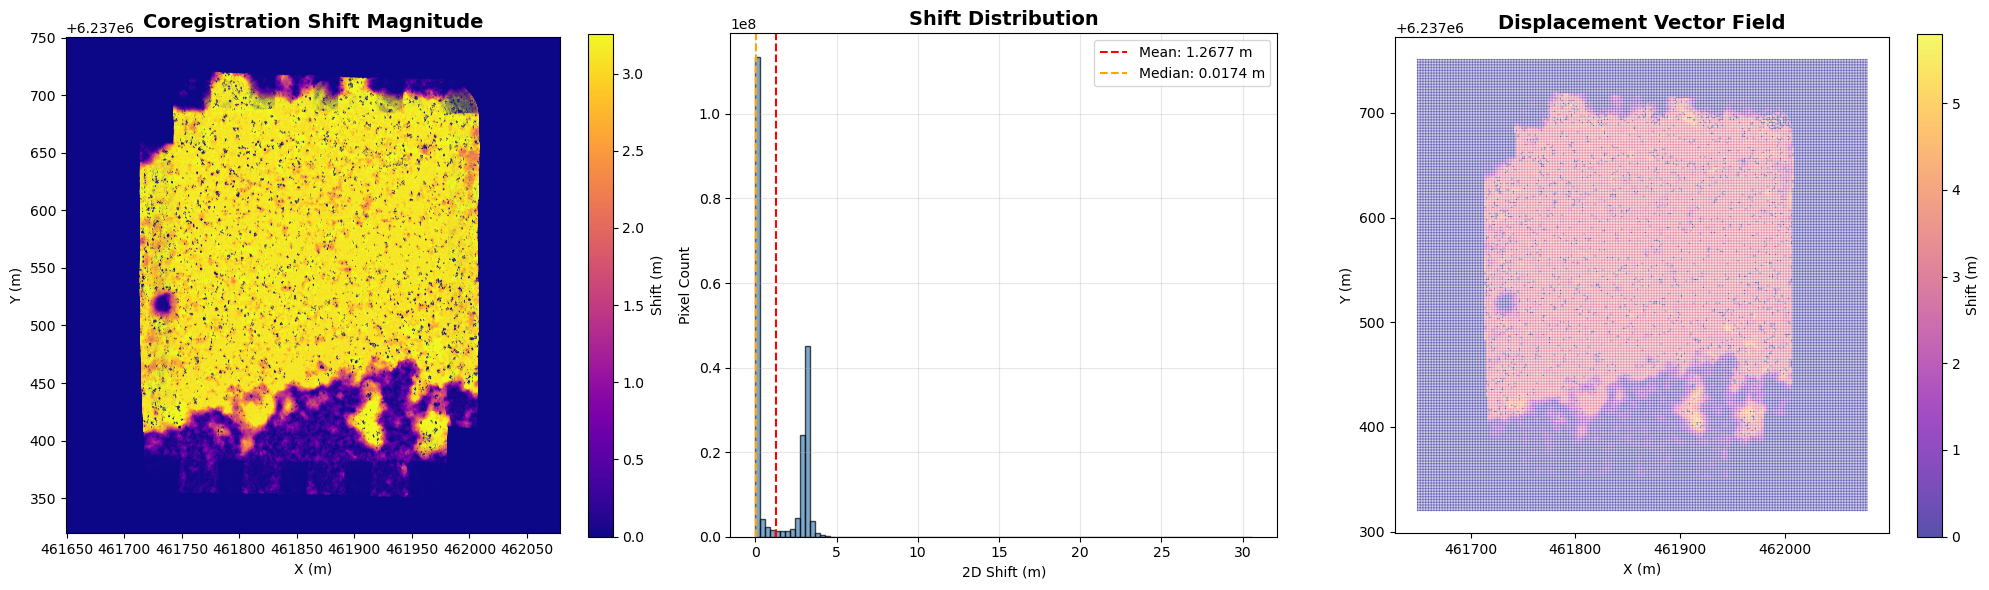


📊 Flow Field Statistics:
   Grid size: 14380 × 14314 pixels
   Mean shift: 1.2677 m
   Median shift: 0.0174 m
   Max shift: 30.6018 m
   95th percentile: 3.2606 m

   Direction (U): 0.3492 m (mean X displacement)
   Direction (V): 1.1014 m (mean Y displacement)


In [8]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

# Load the flow field directly (this is what was applied during coregistration)
#site1
flow_u_path = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/flow_u_03_l2.npy")
flow_v_path = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/flow_v_03_l2.npy")
reference_grid_path = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")


#site11
# flow_u_path = Path("/data/calperumResearch/site2_1_DD0011/imagery/dsm/flow_u_03_l2.npy")
# flow_v_path = Path("/data/calperumResearch/site2_1_DD0011/imagery/dsm/flow_v_03_l2.npy")
# reference_grid_path = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/crop_to_rgb/SASMDD0011_l2_dsm_03_coreg.tif")

try:
    # Load flow fields
    flow_u = np.load(flow_u_path)
    flow_v = np.load(flow_v_path)
    
    # Load reference grid to get transform
    with rasterio.open(reference_grid_path) as src:
        transform = src.transform
        bounds = src.bounds
        
    # Convert flow from pixels to meters
    flow_u_meters = flow_u * transform.a  # pixel width in meters
    flow_v_meters = flow_v * transform.e  # pixel height in meters
    
    # Calculate shift magnitude
    shift_magnitude = np.sqrt(flow_u_meters**2 + flow_v_meters**2)
    
    # Create coordinate grids for the flow field
    H, W = flow_u.shape
    y_coords = np.linspace(bounds.top, bounds.bottom, H)
    x_coords = np.linspace(bounds.left, bounds.right, W)
    X, Y = np.meshgrid(x_coords, y_coords)
    
    # Create visualization
    fig = plt.figure(figsize=(20, 6))
    
    # 1. Shift Magnitude Map
    ax1 = plt.subplot(131)
    im1 = ax1.imshow(shift_magnitude, extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
                     cmap='plasma', vmin=0, vmax=np.percentile(shift_magnitude, 95))
    ax1.set_title('Coregistration Shift Magnitude', fontsize=14, fontweight='bold')
    ax1.set_xlabel('X (m)')
    ax1.set_ylabel('Y (m)')
    ax1.set_aspect('equal')
    plt.colorbar(im1, ax=ax1, label='Shift (m)', fraction=0.046)
    
    # 2. Shift Histogram
    ax2 = plt.subplot(132)
    ax2.hist(shift_magnitude.flatten(), bins=100, color='steelblue', edgecolor='black', alpha=0.7)
    ax2.axvline(shift_magnitude.mean(), color='red', linestyle='--', 
                label=f'Mean: {shift_magnitude.mean():.4f} m')
    ax2.axvline(np.median(shift_magnitude), color='orange', linestyle='--',
                label=f'Median: {np.median(shift_magnitude):.4f} m')
    ax2.set_title('Shift Distribution', fontsize=14, fontweight='bold')
    ax2.set_xlabel('2D Shift (m)')
    ax2.set_ylabel('Pixel Count')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Vector Field (quiver plot of shifts)
    ax3 = plt.subplot(133)
    # Heavy subsampling for quiver (every 50th pixel)
    step = 50
    quiver = ax3.quiver(X[::step, ::step], Y[::step, ::step], 
                       flow_u_meters[::step, ::step], flow_v_meters[::step, ::step],
                       shift_magnitude[::step, ::step],
                       cmap='plasma', scale=5, scale_units='xy', alpha=0.7, width=0.003)
    ax3.set_title('Displacement Vector Field', fontsize=14, fontweight='bold')
    ax3.set_xlabel('X (m)')
    ax3.set_ylabel('Y (m)')
    ax3.set_aspect('equal')
    plt.colorbar(quiver, ax=ax3, label='Shift (m)', fraction=0.046)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n📊 Flow Field Statistics:")
    print(f"   Grid size: {H} × {W} pixels")
    print(f"   Mean shift: {shift_magnitude.mean():.4f} m")
    print(f"   Median shift: {np.median(shift_magnitude):.4f} m")
    print(f"   Max shift: {shift_magnitude.max():.4f} m")
    print(f"   95th percentile: {np.percentile(shift_magnitude, 95):.4f} m")
    print(f"\n   Direction (U): {flow_u_meters.mean():.4f} m (mean X displacement)")
    print(f"   Direction (V): {flow_v_meters.mean():.4f} m (mean Y displacement)")
    
except FileNotFoundError as e:
    print(f"⚠️ File not found: {e}")
    print("Make sure the flow field files exist and paths are correct.")


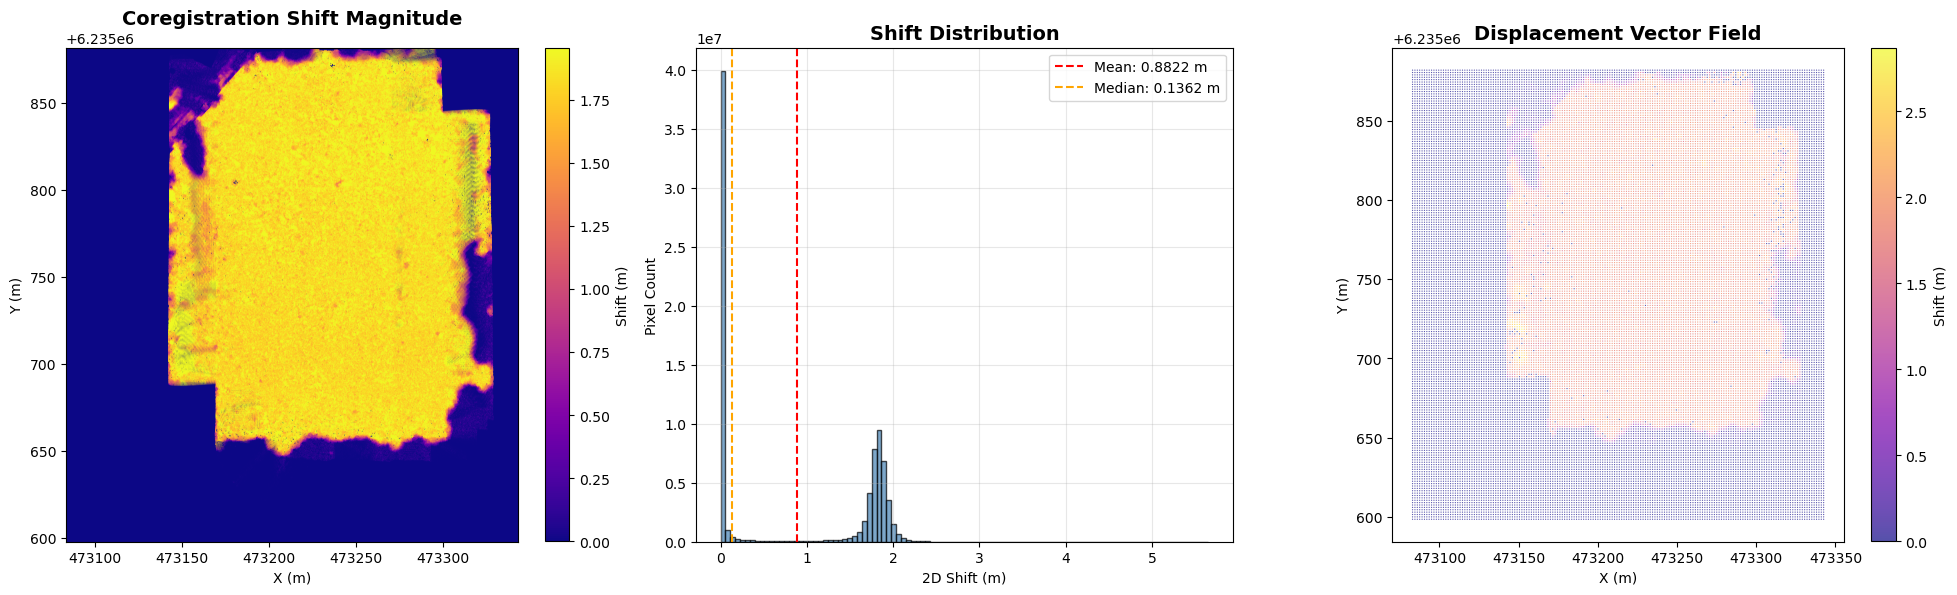


📊 Flow Field Statistics:
   Grid size: 9477 × 8672 pixels
   Mean shift: 0.8822 m
   Median shift: 0.1362 m
   Max shift: 5.6506 m
   95th percentile: 1.9546 m

   Direction (U): 0.6020 m (mean X displacement)
   Direction (V): 0.6292 m (mean Y displacement)


In [5]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

# Load the flow field directly (this is what was applied during coregistration)
#site1
# flow_u_path = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/flow_u_03_l2.npy")
# flow_v_path = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/flow_v_03_l2.npy")
# reference_grid_path = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")


#site11
flow_u_path = Path("/data/calperumResearch/site2_1_DD0011/imagery/dsm/flow_u_03_l2.npy")
flow_v_path = Path("/data/calperumResearch/site2_1_DD0011/imagery/dsm/flow_v_03_l2.npy")
reference_grid_path = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/crop_to_rgb/SASMDD0011_l2_dsm_03_coreg.tif")

try:
    # Load flow fields
    flow_u = np.load(flow_u_path)
    flow_v = np.load(flow_v_path)
    
    # Load reference grid to get transform
    with rasterio.open(reference_grid_path) as src:
        transform = src.transform
        bounds = src.bounds
        
    # Convert flow from pixels to meters
    flow_u_meters = flow_u * transform.a  # pixel width in meters
    flow_v_meters = flow_v * transform.e  # pixel height in meters
    
    # Calculate shift magnitude
    shift_magnitude = np.sqrt(flow_u_meters**2 + flow_v_meters**2)
    
    # Create coordinate grids for the flow field
    H, W = flow_u.shape
    y_coords = np.linspace(bounds.top, bounds.bottom, H)
    x_coords = np.linspace(bounds.left, bounds.right, W)
    X, Y = np.meshgrid(x_coords, y_coords)
    
    # Create visualization
    fig = plt.figure(figsize=(20, 6))
    
    # 1. Shift Magnitude Map
    ax1 = plt.subplot(131)
    im1 = ax1.imshow(shift_magnitude, extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
                     cmap='plasma', vmin=0, vmax=np.percentile(shift_magnitude, 95))
    ax1.set_title('Coregistration Shift Magnitude', fontsize=14, fontweight='bold')
    ax1.set_xlabel('X (m)')
    ax1.set_ylabel('Y (m)')
    ax1.set_aspect('equal')
    plt.colorbar(im1, ax=ax1, label='Shift (m)', fraction=0.046)
    
    # 2. Shift Histogram
    ax2 = plt.subplot(132)
    ax2.hist(shift_magnitude.flatten(), bins=100, color='steelblue', edgecolor='black', alpha=0.7)
    ax2.axvline(shift_magnitude.mean(), color='red', linestyle='--', 
                label=f'Mean: {shift_magnitude.mean():.4f} m')
    ax2.axvline(np.median(shift_magnitude), color='orange', linestyle='--',
                label=f'Median: {np.median(shift_magnitude):.4f} m')
    ax2.set_title('Shift Distribution', fontsize=14, fontweight='bold')
    ax2.set_xlabel('2D Shift (m)')
    ax2.set_ylabel('Pixel Count')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Vector Field (quiver plot of shifts)
    ax3 = plt.subplot(133)
    # Heavy subsampling for quiver (every 50th pixel)
    step = 50
    quiver = ax3.quiver(X[::step, ::step], Y[::step, ::step], 
                       flow_u_meters[::step, ::step], flow_v_meters[::step, ::step],
                       shift_magnitude[::step, ::step],
                       cmap='plasma', scale=5, scale_units='xy', alpha=0.7, width=0.003)
    ax3.set_title('Displacement Vector Field', fontsize=14, fontweight='bold')
    ax3.set_xlabel('X (m)')
    ax3.set_ylabel('Y (m)')
    ax3.set_aspect('equal')
    plt.colorbar(quiver, ax=ax3, label='Shift (m)', fraction=0.046)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n📊 Flow Field Statistics:")
    print(f"   Grid size: {H} × {W} pixels")
    print(f"   Mean shift: {shift_magnitude.mean():.4f} m")
    print(f"   Median shift: {np.median(shift_magnitude):.4f} m")
    print(f"   Max shift: {shift_magnitude.max():.4f} m")
    print(f"   95th percentile: {np.percentile(shift_magnitude, 95):.4f} m")
    print(f"\n   Direction (U): {flow_u_meters.mean():.4f} m (mean X displacement)")
    print(f"   Direction (V): {flow_v_meters.mean():.4f} m (mean Y displacement)")
    
except FileNotFoundError as e:
    print(f"⚠️ File not found: {e}")
    print("Make sure the flow field files exist and paths are correct.")
